<a href="https://colab.research.google.com/github/ralph-Jung/AI-Class/blob/main/6%EC%A3%BC%EC%B0%A8/10_12_abalone_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
    mean_squared_error, mean_absolute_error, r2_score,
)

In [7]:
df=pd.read_csv("/content/drive/MyDrive/Colab Notebooks/abalone.csv")

In [8]:
# 1. 입력 / 정답
#    Sex는 이제 입력이므로 원-핫 인코딩 (Sex_F, Sex_I, Sex_M 열 생성)
X_df = pd.get_dummies(df.drop(columns=["id", "Rings"]), columns=["Sex"])
X = X_df.values.astype("float32")
y = df["Rings"].values.astype("float32")
print("입력 변수:", X_df.columns.tolist())   # 7개 측정값 + Sex 3개 = 10개

입력 변수: ['Length', 'Diameter', 'Height', 'Whole_weight', 'Shucked_weight', 'Viscera_weight', 'Shell_weight', 'Sex_F', 'Sex_I', 'Sex_M']


In [9]:
# 2. 분할
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X, y, test_size=0.2, random_state=42)


In [10]:
# 3. 정규화 (입력만. 정답 Rings는 그대로)
scaler = StandardScaler()
Xr_train = scaler.fit_transform(Xr_train)
Xr_test = scaler.transform(Xr_test)

In [11]:
# 4. 모델: 연속값 하나를 예측하므로 출력 노드 1개, 활성화 함수 없음(linear)
model_reg = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(Xr_train.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1),
])
model_reg.compile(optimizer="adam", loss="mse", metrics=["mae"])

early = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True)

history_reg = model_reg.fit(
    Xr_train, yr_train,
    epochs=200, batch_size=32,
    validation_split=0.2, callbacks=[early], verbose=1)

Epoch 1/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 66.6739 - mae: 7.1848 - val_loss: 24.1062 - val_mae: 3.9392
Epoch 2/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 16.6518 - mae: 3.0019 - val_loss: 8.9656 - val_mae: 2.1317
Epoch 3/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 8.1954 - mae: 1.9457 - val_loss: 5.3187 - val_mae: 1.6233
Epoch 4/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 6.3782 - mae: 1.7250 - val_loss: 4.8054 - val_mae: 1.5173
Epoch 5/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.8057 - mae: 1.6766 - val_loss: 4.5897 - val_mae: 1.5463
Epoch 6/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.5243 - mae: 1.6600 - val_loss: 4.3864 - val_mae: 1.4874
Epoch 7/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.2860 - mae: 1.6209 - val_loss: 4.3481 - val_mae: 1.4735
Epoch 8/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.1613 - mae: 1.6066 - val_loss: 4.2011 - val_mae: 1.4453
Epoch 9/200
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.

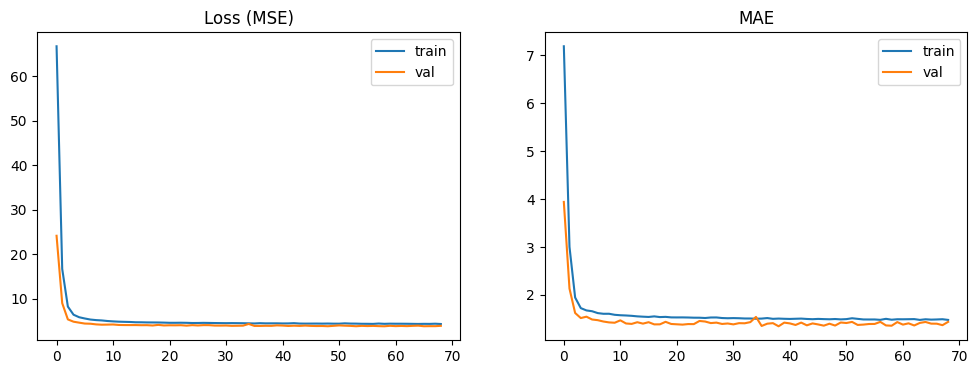

In [12]:
# 5. 학습 곡선
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_reg.history["loss"], label="train")
axes[0].plot(history_reg.history["val_loss"], label="val")
axes[0].set_title("Loss (MSE)"); axes[0].legend()
axes[1].plot(history_reg.history["mae"], label="train")
axes[1].plot(history_reg.history["val_mae"], label="val")
axes[1].set_title("MAE"); axes[1].legend()
plt.show()

In [13]:
# 6. 평가: (836, 1) → (836,) 로 펴기
yr_pred = model_reg.predict(Xr_test).ravel()

mse = mean_squared_error(yr_test, yr_pred)
print("MSE :", mse)
print("RMSE:", np.sqrt(mse))
print("MAE :", mean_absolute_error(yr_test, yr_pred))
print("R²  :", r2_score(yr_test, yr_pred))

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
MSE : 4.485424041748047
RMSE: 2.11788197068393
MAE : 1.4982103109359741
R²  : 0.5856501460075378


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


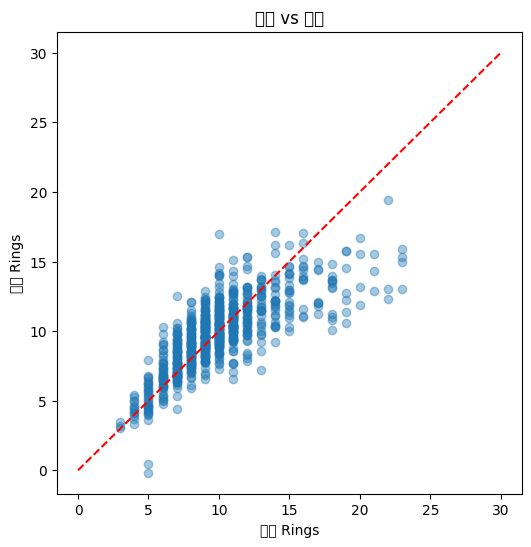

In [14]:
# 7. 실제값 vs 예측값 (회귀에서 혼동 행렬 대신 보는 그래프)
plt.figure(figsize=(6, 6))
plt.scatter(yr_test, yr_pred, alpha=0.4)
plt.plot([0, 30], [0, 30], "r--")          # 이 대각선 위에 있으면 정확히 맞힌 것
plt.xlabel("실제 Rings"); plt.ylabel("예측 Rings")
plt.title("실제 vs 예측")
plt.show()